In [1]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from sklearn.metrics import confusion_matrix, classification_report

BASE_DIR = os.path.abspath(".")
DATA_DIR = os.path.join(BASE_DIR, "data", "rps")
REAL_DIR = os.path.join(BASE_DIR, "data", "custom_test", "rps_real")
RESULTS_DIR = os.path.join(BASE_DIR, "results")
MODELS_DIR = os.path.join(BASE_DIR, "models")

print(f"TensorFlow Version: {tf.__version__}")

TensorFlow Version: 2.21.0


In [ ]:
with open(os.path.join(RESULTS_DIR, "task4_rps_summary.json")) as f:
    rps_summary = json.load(f)

model_path = os.path.join(MODELS_DIR, "rps_model.keras")
model = tf.keras.models.load_model(model_path)
model.summary()

Model: "sequential"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼─────────────────────

Підсумкова тренувальна точність: 96.83%
Підсумкова валідаційна точність: 97.85%


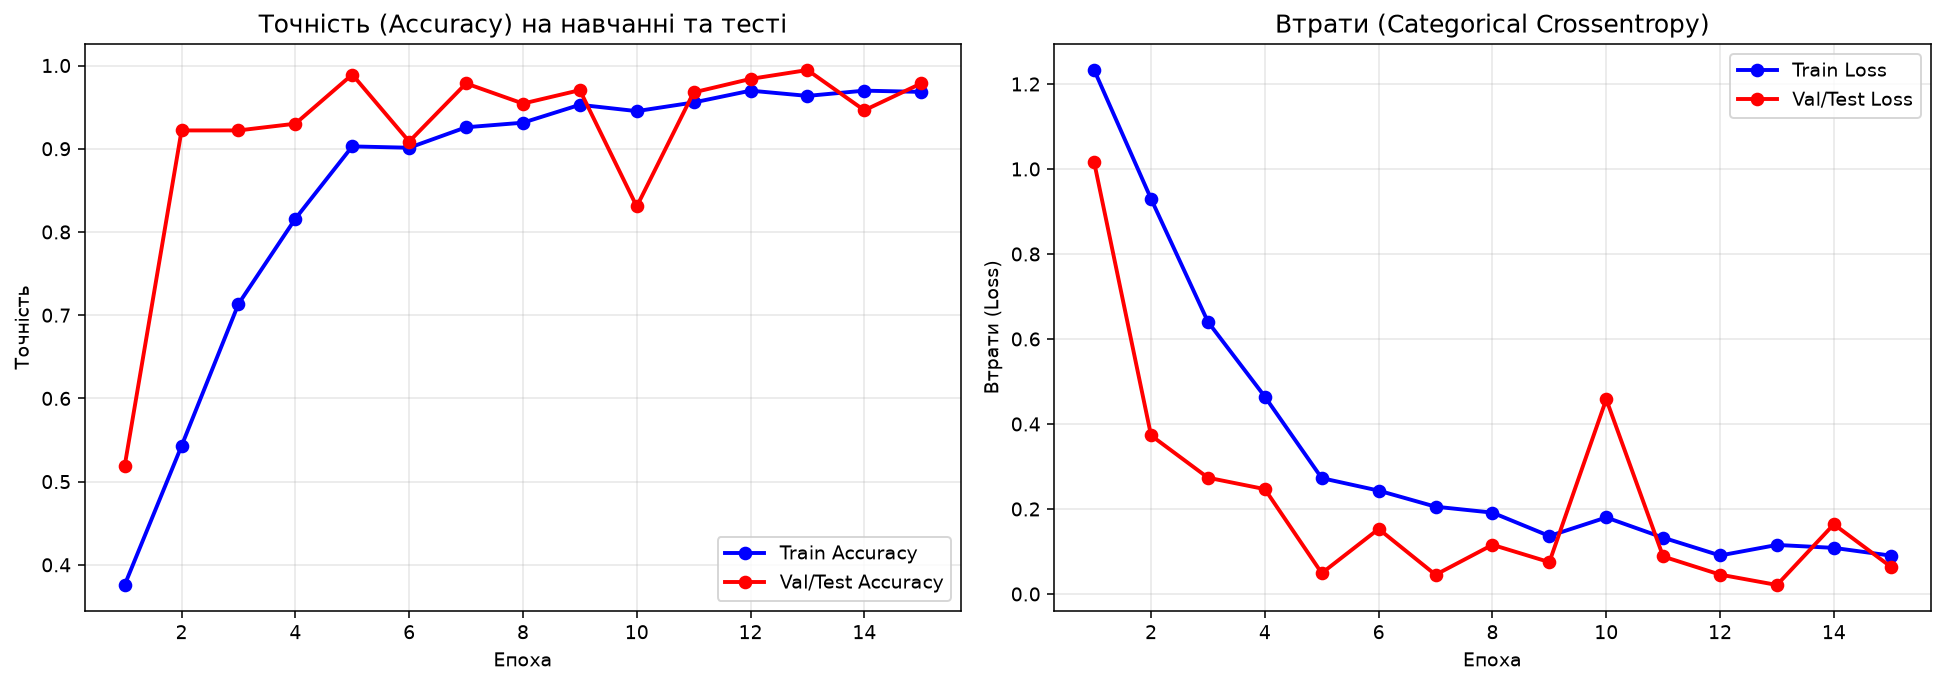

In [ ]:
history = rps_summary["history"]
epochs = range(1, len(history["accuracy"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs, history["accuracy"], 'bo-', label='Train Accuracy', linewidth=2)
axes[0].plot(epochs, history["val_accuracy"], 'ro-', label='Val/Test Accuracy', linewidth=2)
axes[0].set_title('Точність (Accuracy) на навчанні та тесті', fontsize=13)
axes[0].set_xlabel('Епоха')
axes[0].set_ylabel('Точність')
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc='lower right')

axes[1].plot(epochs, history["loss"], 'bo-', label='Train Loss', linewidth=2)
axes[1].plot(epochs, history["val_loss"], 'ro-', label='Val/Test Loss', linewidth=2)
axes[1].set_title('Втрати (Categorical Crossentropy)', fontsize=13)
axes[1].set_xlabel('Епоха')
axes[1].set_ylabel('Втрати (Loss)')
axes[1].grid(True, alpha=0.3)
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

print(f"Підсумкова тренувальна точність: {history['accuracy'][-1]*100:.2f}%")
print(f"Підсумкова валідаційна точність: {history['val_accuracy'][-1]*100:.2f}%")

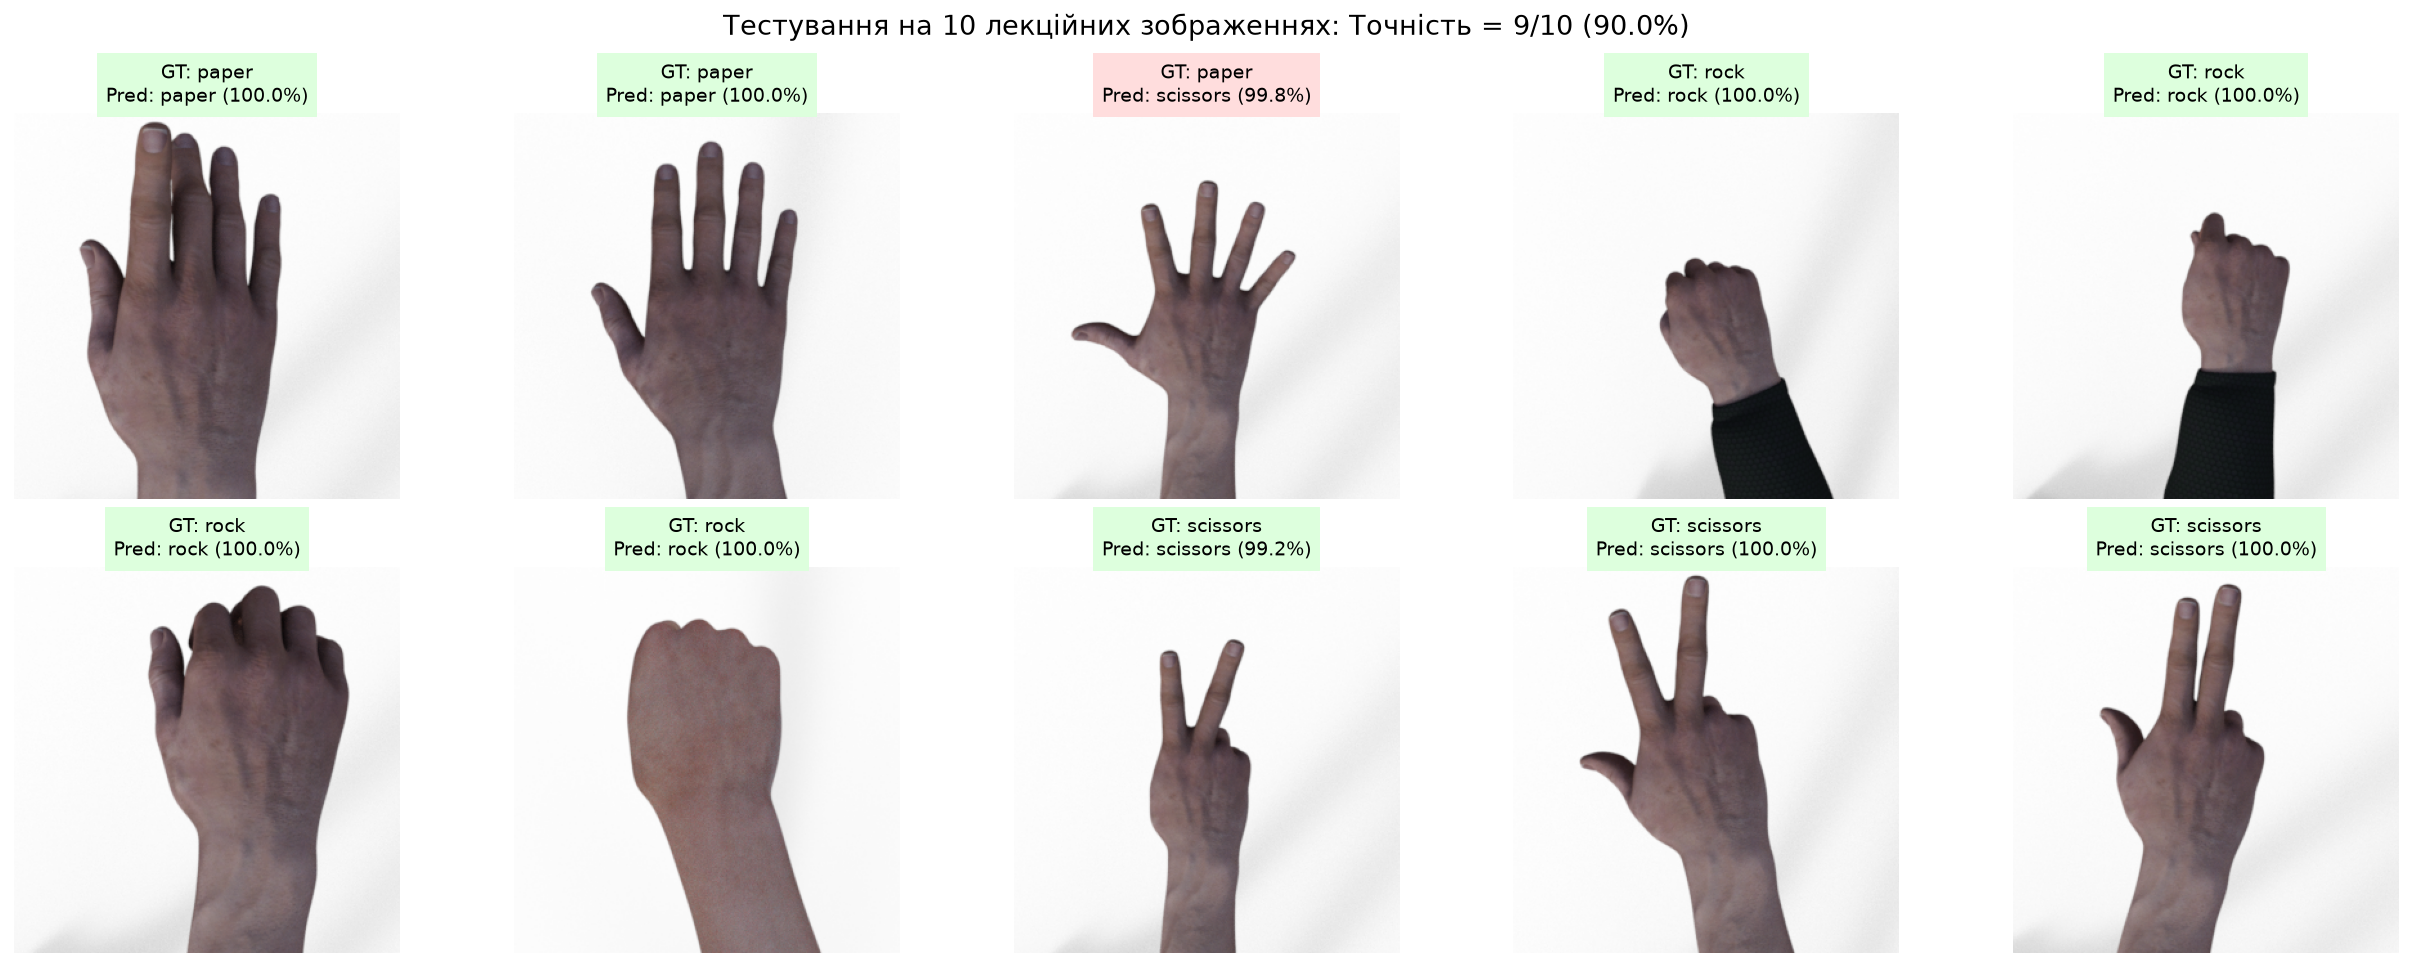

In [ ]:
val_items = rps_summary.get("lecture_val_results") or rps_summary.get("lecture_results", [])

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
axes = axes.flatten()

correct_count = 0
for idx, item in enumerate(val_items):
    fname = item.get("filename") or item.get("file")

    img_path = None
    for root, dirs, files in os.walk(os.path.join(DATA_DIR, "validation")):
        if fname in files:
            img_path = os.path.join(root, fname)
            break
    
    if img_path and os.path.exists(img_path):
        img = Image.open(img_path).convert('RGB')
        axes[idx].imshow(img)
    
    gt = item.get("true_class") or item.get("true")
    pred = item.get("pred_class") or item.get("pred")
    conf = item["confidence"]
    is_corr = item["correct"]
    if is_corr:
        correct_count += 1
        
    axes[idx].set_title(
        f"GT: {gt}\nPred: {pred} ({conf*100:.1f}%)",
        fontsize=10,
        backgroundcolor='#ddffdd' if is_corr else '#ffdddd'
    )
    axes[idx].axis('off')

plt.suptitle(f"Тестування на 10 лекційних зображеннях: Точність = {correct_count}/{len(val_items)} ({correct_count/len(val_items)*100:.1f}%)", fontsize=14)
plt.tight_layout()
plt.show()

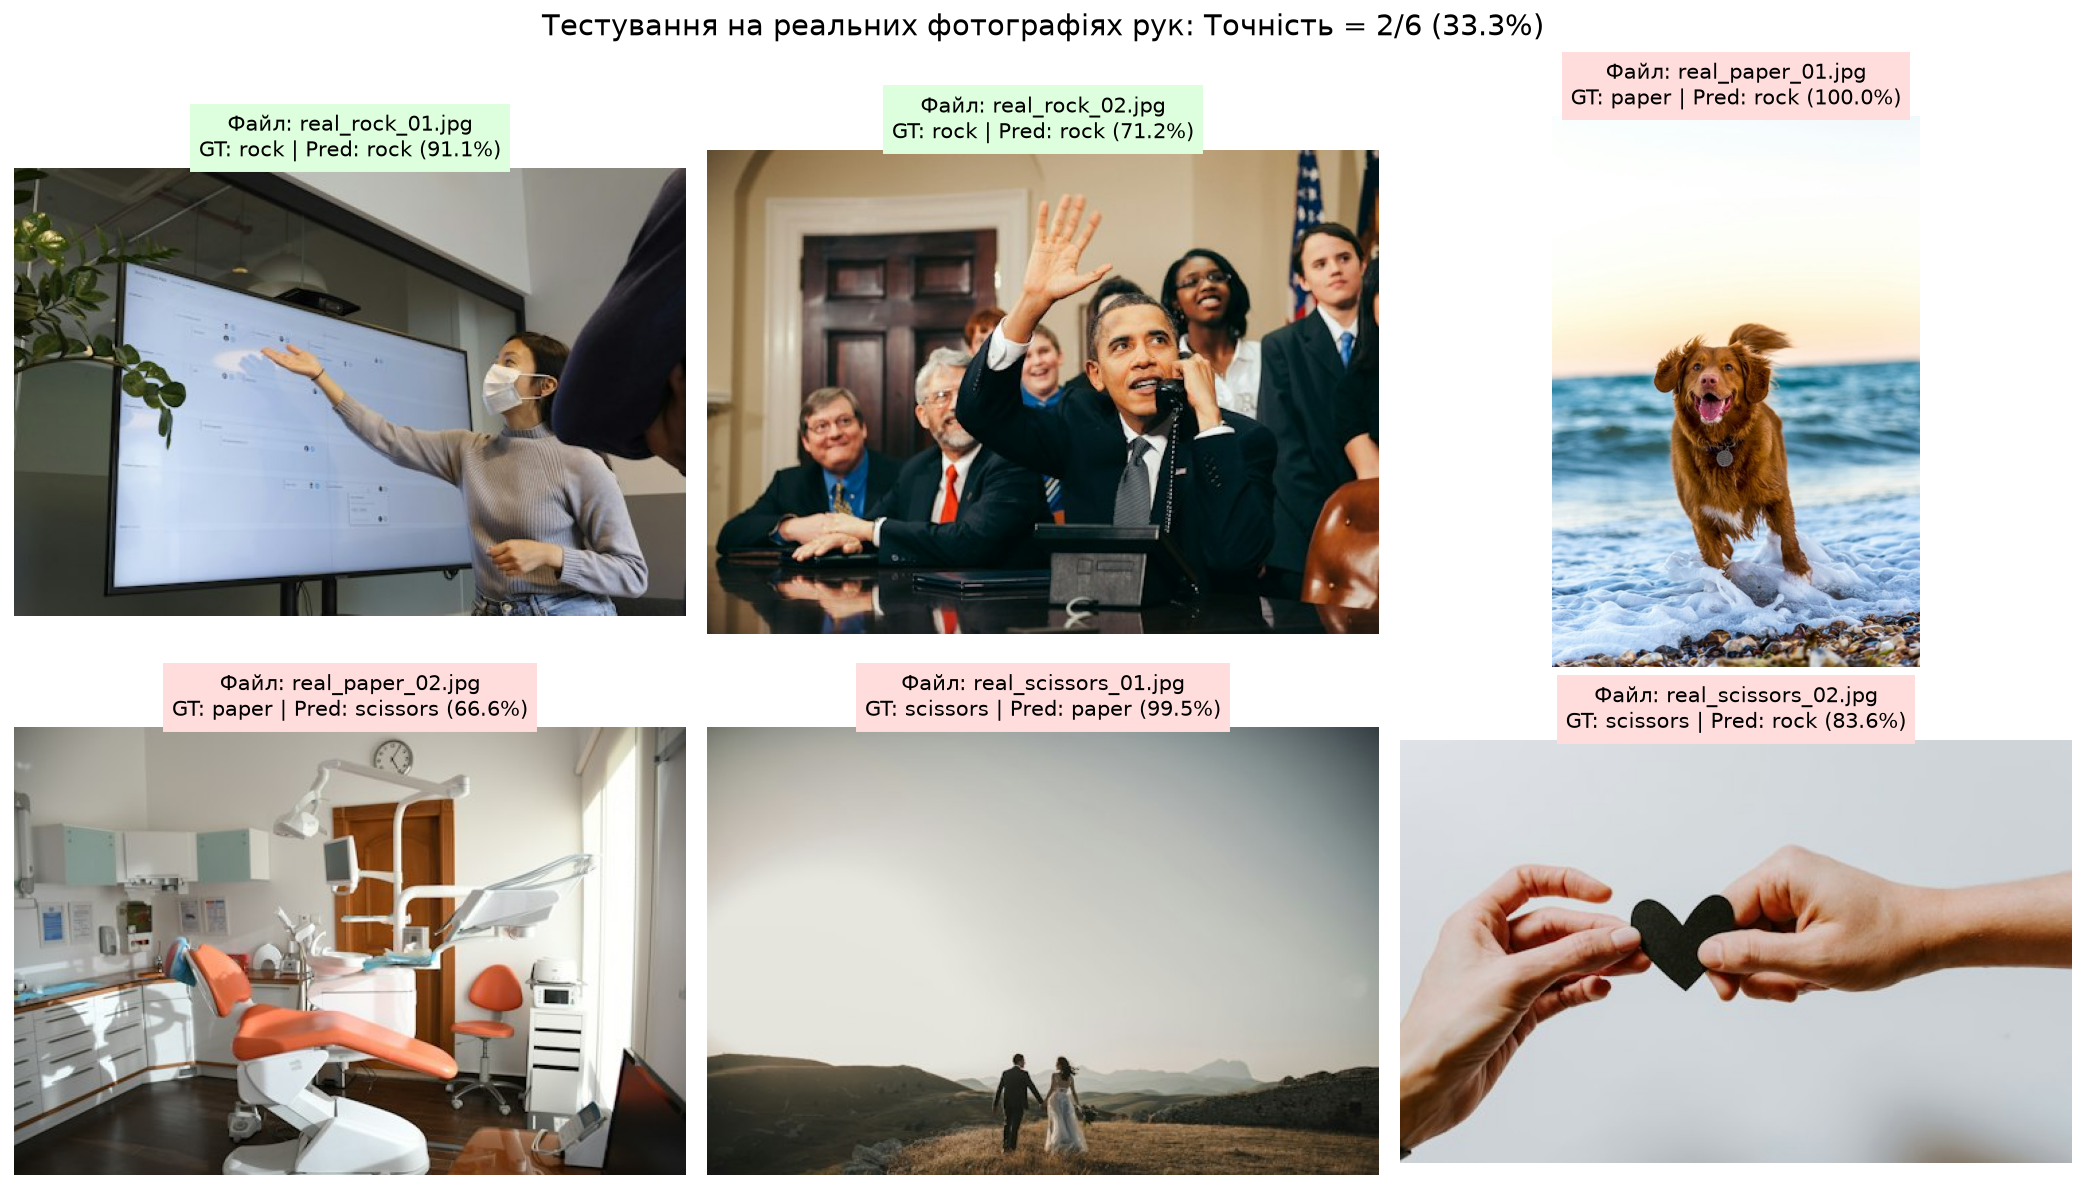

In [5]:
real_items = rps_summary.get("real_photo_results") or rps_summary.get("real_photos_results", [])

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

real_correct = 0
for idx, item in enumerate(real_items):
    fname = item.get("filename") or item.get("file")
    img_path = os.path.join(REAL_DIR, fname)
    if os.path.exists(img_path):
        img = Image.open(img_path).convert('RGB')
        axes[idx].imshow(img)
        
    gt = item.get("true_class") or item.get("true")
    pred = item.get("pred_class") or item.get("pred")
    conf = item["confidence"]
    is_corr = item["correct"]
    if is_corr:
        real_correct += 1
        
    axes[idx].set_title(
        f"Файл: {fname}\nGT: {gt} | Pred: {pred} ({conf*100:.1f}%)",
        fontsize=11,
        backgroundcolor='#ddffdd' if is_corr else '#ffdddd'
    )
    axes[idx].axis('off')

plt.suptitle(f"Тестування на реальних фотографіях рук: Точність = {real_correct}/{len(real_items)} ({real_correct/len(real_items)*100:.1f}%)", fontsize=15)
plt.tight_layout()
plt.show()

In [6]:
print(f"{'Назва файлу':<25} | {'Істинний жест':<15} | {'Передбачення':<15} | {'Впевненість':<12} | Статус")
print("-" * 80)
for it in real_items:
    fname = it.get("filename") or it.get("file")
    gt = it.get("true_class") or it.get("true")
    pred = it.get("pred_class") or it.get("pred")
    status = "УСПІХ (Correct)" if it['correct'] else "ПОМИЛКА (Mistake)"
    print(f"{fname:<25} | {gt:<15} | {pred:<15} | {it['confidence']*100:>10.2f}% | {status}")

Назва файлу               | Істинний жест   | Передбачення    | Впевненість  | Статус
--------------------------------------------------------------------------------
real_rock_01.jpg          | rock            | rock            |      91.05% | УСПІХ (Correct)
real_rock_02.jpg          | rock            | rock            |      71.23% | УСПІХ (Correct)
real_paper_01.jpg         | paper           | rock            |      99.96% | ПОМИЛКА (Mistake)
real_paper_02.jpg         | paper           | scissors        |      66.57% | ПОМИЛКА (Mistake)
real_scissors_01.jpg      | scissors        | paper           |      99.52% | ПОМИЛКА (Mistake)
real_scissors_02.jpg      | scissors        | rock            |      83.64% | ПОМИЛКА (Mistake)
